# 06_run_nsga2: Step 6 - final NSGA-II runs and accuracy assessment.

```
For each case study and each hyperparameter set (paper Tables 3/6, and the sets
tuned by PSO, GA and HHO): 30 seeds (1-30, as in the paper), 25,000 function
evaluations each (= the paper's 500 generations x 50).

Accuracy of NSGA-II is measured against a high-budget reference front
(5 runs, population 200, 200,000 evaluations, merged with every final front):
  * HV ratio  = HV(run) / HV(reference front)   (1 = reaches the reference front)
  * IGD+      = distance to the reference front (0 = reaches it)
Objective attainment: energy saving vs the 24 degC baseline, comfort gain, and the
share of Pareto solutions in which every occupant has |PMV| <= 0.5 (ISO 7730 cat. B).
Outputs -> outputs/nsga2/, figures.
Script asli: `scripts/06_run_nsga2.py` [--seeds 30] [--evals 25000] — parameter kini diatur di sel `args` di bawah.
```

Dikonversi dari `scripts/06_run_nsga2.py`. Jalankan dari folder `notebooks/`.

In [1]:
from types import SimpleNamespace
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.stats import mannwhitneyu

ROOT = Path.cwd().resolve().parent   # notebook runs from AI-OBEP-MLPaper/notebooks
sys.path.insert(0, str(ROOT / "src"))
from obep_mlpaper.layout import OFFICE, T_MAX, T_MIN, case_study_1, case_study_2, evaluate
from obep_mlpaper.nsga import HV_REF, PAPER_HP, igd_plus, nondominated, run_nsga2
from obep_mlpaper.plotstyle import ALGO_COLORS, INK, INK2, NEUTRAL, plt
from obep_mlpaper.surrogate import Surrogate
from pymoo.indicators.hv import HV

# Parameters (were command-line arguments in the script; edit here)
args = SimpleNamespace(seeds=30, evals=25_000, ref_runs=5, ref_evals=200_000)

sur = Surrogate.load(ROOT / "outputs" / "models" / "surrogate.joblib").single_thread()
out = ROOT / "outputs" / "nsga2"
fig_dir = ROOT / "outputs" / "figures"
tuned = json.loads((out / "nsga2_tuned_hyperparameters.json").read_text())
COLORS = {"Paper HP": NEUTRAL, **{f"{a}-tuned": c for a, c in ALGO_COLORS.items()}}

In [2]:
def worst_abs_pmv(r):
    p = np.where(r["occ"] > 0, np.abs(r["pmv"]), 0.0)
    return p.max(axis=1)

In [3]:
summary = {}
for sc in (case_study_1(), case_study_2()):
    configs = {"Paper HP": PAPER_HP[sc.name], **{f"{a}-tuned": hp for a, hp in tuned[sc.name].items()}}
    base = evaluate(sc, sur, sc.baseline()[None])
    f0 = base["F"][0]

    jobs = [(cfg, s) for cfg in configs for s in range(1, args.seeds + 1)]
    res = Parallel(n_jobs=2)(delayed(run_nsga2)(sc, sur, configs[c], s, args.evals, 25) for c, s in jobs)
    ref_runs = Parallel(n_jobs=2)(delayed(run_nsga2)(
        sc, sur, dict(pop_size=200, p_m=0.5, eta_m=1.0, p_c=0.9, sigma_t=0.3), 1000 + s, args.ref_evals)
        for s in range(args.ref_runs))

    allF = np.vstack([r["F"] for r in res + ref_runs])
    allX = np.vstack([r["X"] for r in res + ref_runs])
    nd = nondominated(allF)
    refF, refX = allF[nd], allX[nd]
    _, keep = np.unique(np.round(refF, 9), axis=0, return_index=True)
    refF, refX = refF[keep], refX[keep]
    hv_ref = float(HV(ref_point=np.full(2, HV_REF))(refF / f0))

    rows, fronts, conv = [], [], []
    for (cfg, s), r in zip(jobs, res):
        ev = evaluate(sc, sur, r["X"])
        ok = worst_abs_pmv(ev) <= 0.5
        rows.append(dict(config=cfg, seed=s, n_solutions=len(r["F"]), hv=r["hv"], hv_ratio=r["hv"] / hv_ref,
                         igd_plus=igd_plus(r["F"], refF, f0),
                         best_f_cost=r["F"][:, 0].min(), best_f_tc=r["F"][:, 1].min(),
                         max_energy_saving_pct=100 * (1 - r["F"][:, 0].min() / f0[0]),
                         max_comfort_gain_pct=100 * (1 - r["F"][:, 1].min() / f0[1]),
                         share_all_pmv_within_0_5=float(ok.mean())))
        fronts += [dict(config=cfg, seed=s, f_cost=f[0], f_tc=f[1], **{f"x{i + 1}": v for i, v in enumerate(x)})
                   for f, x in zip(r["F"], r["X"])]
        conv += [dict(config=cfg, seed=s, gen=gen, n_eval=ne, hv=hv) for gen, ne, hv in r["trace"]]
    runs = pd.DataFrame(rows)
    runs.to_csv(out / f"{sc.name}_runs.csv", index=False)
    pd.DataFrame(fronts).to_csv(out / f"{sc.name}_fronts.csv", index=False)
    conv = pd.DataFrame(conv)
    conv.to_csv(out / f"{sc.name}_hv_convergence.csv", index=False)
    pd.DataFrame(np.column_stack([refF, refX]),
                 columns=["f_cost", "f_tc"] + [f"x{i + 1}" for i in range(refX.shape[1])]).to_csv(
        out / f"{sc.name}_reference_front.csv", index=False)

    agg = runs.groupby("config").agg(
        hv_mean=("hv", "mean"), hv_std=("hv", "std"), hv_ratio_mean=("hv_ratio", "mean"),
        hv_ratio_min=("hv_ratio", "min"), igd_plus_mean=("igd_plus", "mean"), igd_plus_std=("igd_plus", "std"),
        n_solutions=("n_solutions", "mean"), f_cost_best_mean=("best_f_cost", "mean"),
        f_tc_best_mean=("best_f_tc", "mean"), energy_saving_pct_mean=("max_energy_saving_pct", "mean"),
        comfort_gain_pct_mean=("max_comfort_gain_pct", "mean"),
        share_pmv_ok_mean=("share_all_pmv_within_0_5", "mean")).reindex(list(configs))
    # Wilcoxon rank-sum: each tuned set vs paper HP (HV, two-sided)
    agg["p_value_hv_vs_paper"] = [np.nan if c == "Paper HP" else
                                  mannwhitneyu(runs[runs.config == c].hv, runs[runs.config == "Paper HP"].hv).pvalue
                                  for c in agg.index]
    agg.to_csv(out / f"{sc.name}_summary_by_config.csv")
    print(f"\n== {sc.name}: baseline (24 degC) f_cost={f0[0]:.3f} kW f_tc={f0[1]:.3f}; HV(ref front)={hv_ref:.4f}")
    print(agg.round(4).to_string())

    # Solutions A (min energy) and B (best comfort) from the reference front
    def describe(x, f):
        e = evaluate(sc, sur, x[None])
        return dict(f_cost=float(f[0]), f_tc=float(f[1]),
                    energy_saving_pct=float(100 * (1 - f[0] / f0[0])),
                    comfort_gain_pct=float(100 * (1 - f[1] / f0[1])),
                    walls=np.round(e["W"][0], 2).tolist(), zone_setpoints=np.round(e["setpoints"][0], 2).tolist(),
                    room_area=np.round(e["area"][0], 1).tolist(), occupants=e["occ"][0].tolist(),
                    room_T=np.round(e["T"][0], 2).tolist(), room_pmv=np.round(e["pmv"][0], 3).tolist(),
                    worst_abs_pmv=float(worst_abs_pmv(e)[0]))

    # A / B from the reference front. C = lowest energy among ALL final solutions in which
    # every occupant has |PMV| <= 0.5 (a worst-room condition, so C can lie off the front,
    # which is non-dominated on the *average* |PMV|).
    sols = {"A (min energy)": (refX[refF[:, 0].argmin()], refF[refF[:, 0].argmin()]),
            "B (best comfort)": (refX[refF[:, 1].argmin()], refF[refF[:, 1].argmin()])}
    ok_all = np.where(worst_abs_pmv(evaluate(sc, sur, allX)) <= 0.5)[0]
    if len(ok_all):
        i = ok_all[allF[ok_all, 0].argmin()]
        sols["C (min energy with all |PMV|<=0.5)"] = (allX[i], allF[i])
    info = dict(baseline_24C=dict(f_cost=float(f0[0]), f_tc=float(f0[1]),
                                  room_pmv=np.round(base["pmv"][0], 3).tolist()),
                hv_reference_front=hv_ref, n_reference_points=len(refF),
                **{k: describe(x, f) for k, (x, f) in sols.items()})
    best_cfg = agg.hv_mean.idxmax()
    info["best_config_by_mean_hv"] = best_cfg
    info["best_config_hyperparameters"] = configs[best_cfg]
    (out / f"{sc.name}_summary.json").write_text(json.dumps(info, indent=2))
    summary[sc.name] = info

    # -------- figures: Pareto, HV convergence, layouts
    fr = pd.DataFrame(fronts)
    fig, ax = plt.subplots(figsize=(5.0, 3.8))
    for cfg in configs:
        sub = fr[fr.config == cfg]
        ax.scatter(sub.f_cost / f0[0], sub.f_tc / f0[1], s=6, color=COLORS[cfg], alpha=0.25,
                   edgecolor="none", label=f"{cfg} (30 runs)")
    o = np.argsort(refF[:, 0])
    ax.plot(refF[o, 0] / f0[0], refF[o, 1] / f0[1], color=INK, lw=1.2, label="Reference front")
    ax.scatter([1], [1], marker="s", s=40, color=INK, zorder=5)
    ax.annotate("Baseline 24 °C", (1, 1), xytext=(-6, -12), textcoords="offset points", ha="right",
                fontsize=8, color=INK2)
    for k, (_, f) in sols.items():
        ax.scatter(f[0] / f0[0], f[1] / f0[1], s=36, facecolor="white", edgecolor=INK, zorder=6)
        ax.annotate(k.split(" ")[0], (f[0] / f0[0], f[1] / f0[1]), xytext=(5, 4),
                    textcoords="offset points", fontsize=9, fontweight="bold")
    ax.set(xlabel="Energy f_cost / baseline", ylabel="Comfort penalty f_tc / baseline",
           title=f"{sc.name}: NSGA-II Pareto fronts")
    ax.legend(fontsize=7, markerscale=2, loc="upper left", bbox_to_anchor=(1.02, 1.0))
    fig.savefig(fig_dir / f"fig_{sc.name}_pareto.png")

    fig, ax = plt.subplots(figsize=(4.8, 3.2))
    for cfg in configs:
        cc = conv[conv.config == cfg]
        # resample each run onto a common evaluation grid
        grid = np.linspace(cc.n_eval.min(), args.evals, 60)
        curves = np.array([np.interp(grid, g.n_eval, g.hv) for _, g in cc.groupby("seed")])
        ax.plot(grid, curves.mean(0) / hv_ref, color=COLORS[cfg], lw=2, label=cfg)
    ax.axhline(1, color=INK2, lw=0.8, ls="--")
    ax.set(xlabel="Function evaluations", ylabel="HV / HV(reference front)",
           title=f"{sc.name}: convergence (mean of 30 seeds)")
    ax.legend(fontsize=8)
    fig.savefig(fig_dir / f"fig_{sc.name}_hv_convergence.png")

    fig, axs = plt.subplots(len(sols) + 1, 1, figsize=(9, 1.25 * (len(sols) + 1) + 0.6))
    panels = [("Baseline (24 °C)", sc.baseline(), f0)] + [(k, x, f) for k, (x, f) in sols.items()]
    cmap = plt.get_cmap("Blues")
    for a, (title, x, f) in zip(axs, panels):
        e = evaluate(sc, sur, x[None])
        W = e["W"][0]
        for j in range(sc.n_rooms):
            shade = cmap(0.15 + 0.6 * (e["T"][0, j] - T_MIN) / (T_MAX - T_MIN))
            if sc.room_types[j] != OFFICE:
                shade = "#d9ead3"
            a.add_patch(plt.Rectangle((W[j], 0), W[j + 1] - W[j], sc.B, fc=shade, ec=INK, lw=0.8))
            a.text((W[j] + W[j + 1]) / 2, sc.B / 2,
                   f"{e['area'][0, j]:.1f} m²\n{e['occ'][0, j]} pax\n{e['T'][0, j]:.1f} °C",
                   ha="center", va="center", fontsize=6.5)
        sav, gain = 100 * (1 - f[0] / f0[0]), 100 * (1 - f[1] / f0[1])
        a.set(xlim=(0, sc.L), ylim=(0, sc.B), yticks=[], xticks=[])
        a.set_title(f"{title}: f_cost={f[0]:.2f} kW ({sav:+.1f}% saving), f_tc={f[1]:.3f} ({gain:+.1f}%)",
                    fontsize=8, loc="left")
        a.grid(False)
    fig.tight_layout()
    fig.savefig(fig_dir / f"fig_{sc.name}_layouts.png")
    plt.close("all")

(out / "summary_all_cases.json").write_text(json.dumps(summary, indent=2))


== case1_simple: baseline (24 degC) f_cost=43.130 kW f_tc=0.497; HV(ref front)=1.0268
           hv_mean  hv_std  hv_ratio_mean  hv_ratio_min  igd_plus_mean  igd_plus_std  n_solutions  f_cost_best_mean  f_tc_best_mean  energy_saving_pct_mean  comfort_gain_pct_mean  share_pmv_ok_mean  p_value_hv_vs_paper
config                                                                                                                                                                                                                    
Paper HP    0.9898  0.0055         0.9639        0.9537         0.0118        0.0011      29.9333           33.6502          0.0161                 21.9788                96.7591             0.3286                  NaN
PSO-tuned   1.0149  0.0031         0.9884        0.9823         0.0055        0.0014      29.0000           33.4245          0.0029                 22.5023                99.4183             0.1897                  0.0
GA-tuned    1.0147  0.0032         0.


== case2_watson: baseline (24 degC) f_cost=65.212 kW f_tc=0.642; HV(ref front)=1.1391
           hv_mean  hv_std  hv_ratio_mean  hv_ratio_min  igd_plus_mean  igd_plus_std  n_solutions  f_cost_best_mean  f_tc_best_mean  energy_saving_pct_mean  comfort_gain_pct_mean  share_pmv_ok_mean  p_value_hv_vs_paper
config                                                                                                                                                                                                                    
Paper HP    1.0880  0.0057         0.9551        0.9442         0.0212        0.0022      37.4000           48.3560          0.0225                 25.8476                96.4889             0.5617                  NaN
PSO-tuned   1.1138  0.0088         0.9778        0.9542         0.0214        0.0066      10.0000           47.7733          0.0019                 26.7411                99.6981             0.4900                  0.0
GA-tuned    1.1191  0.0078         0.

7208

## Gambar yang dihasilkan

fig_case1_simple_pareto.png


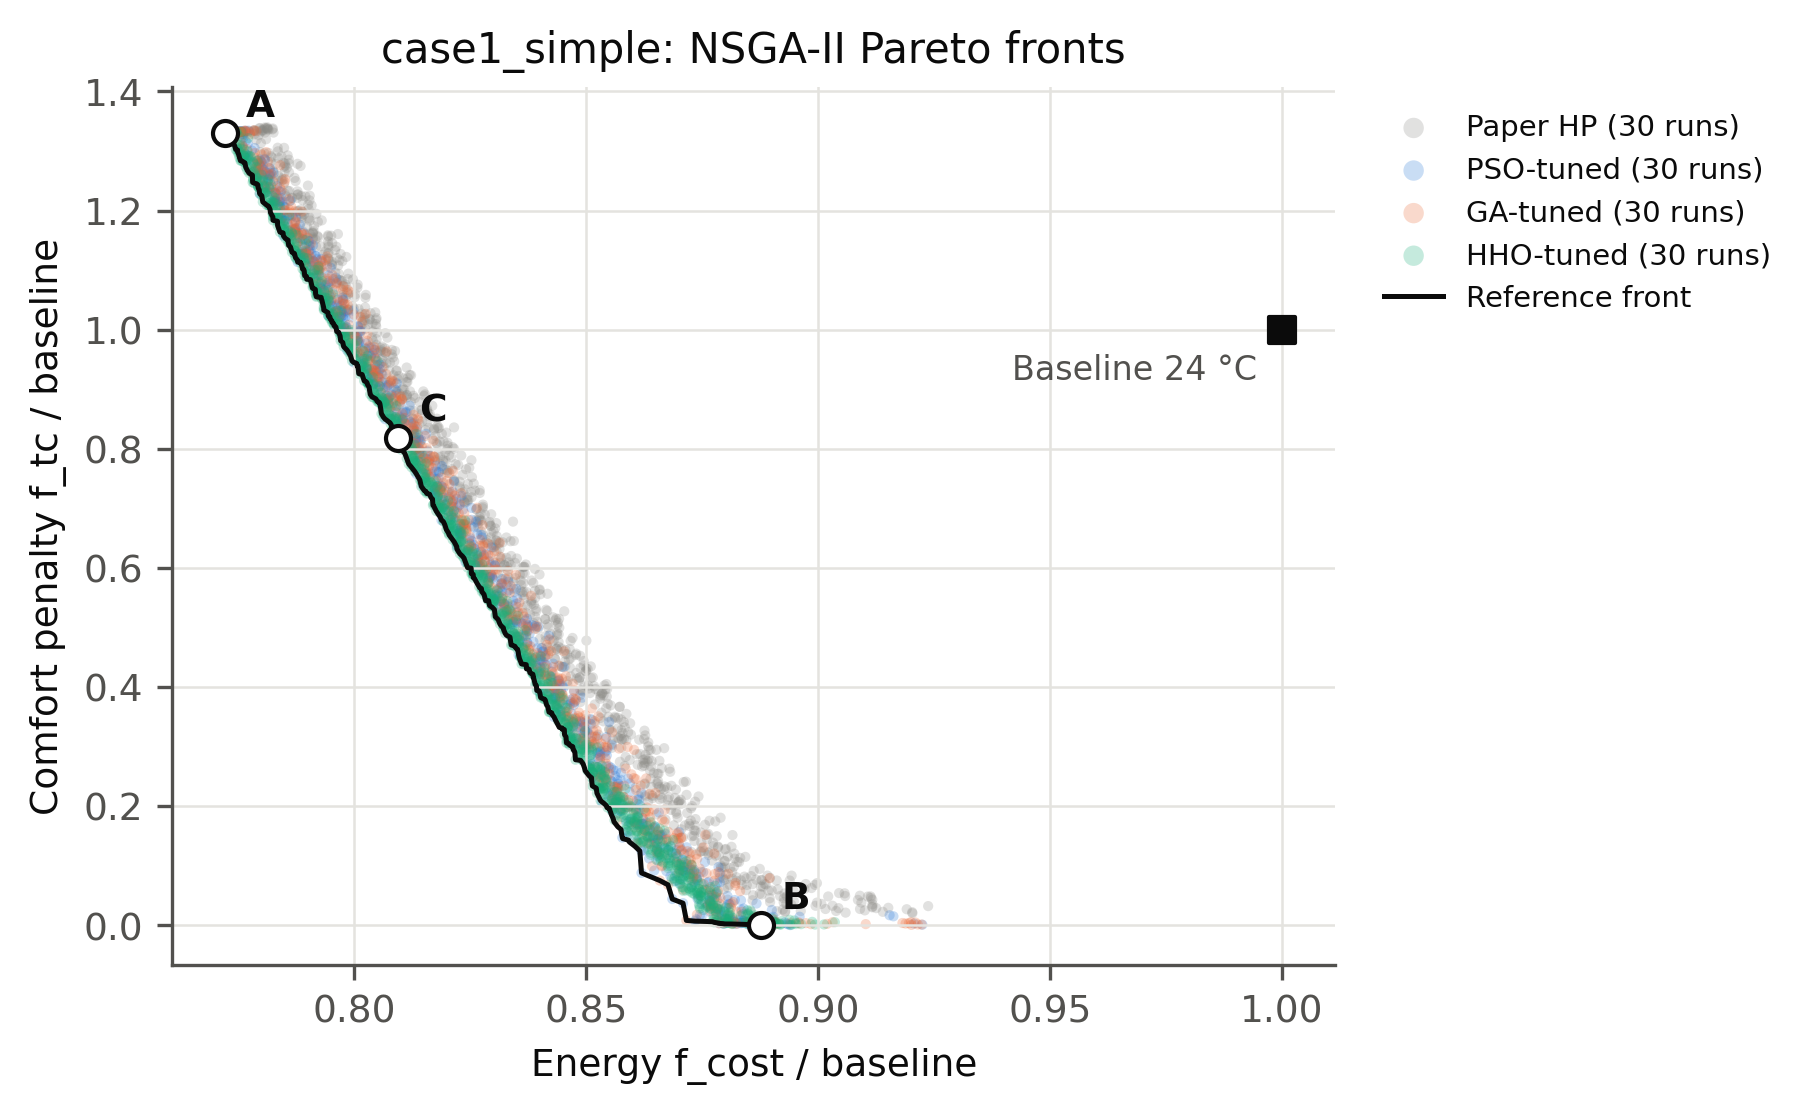

fig_case1_simple_hv_convergence.png


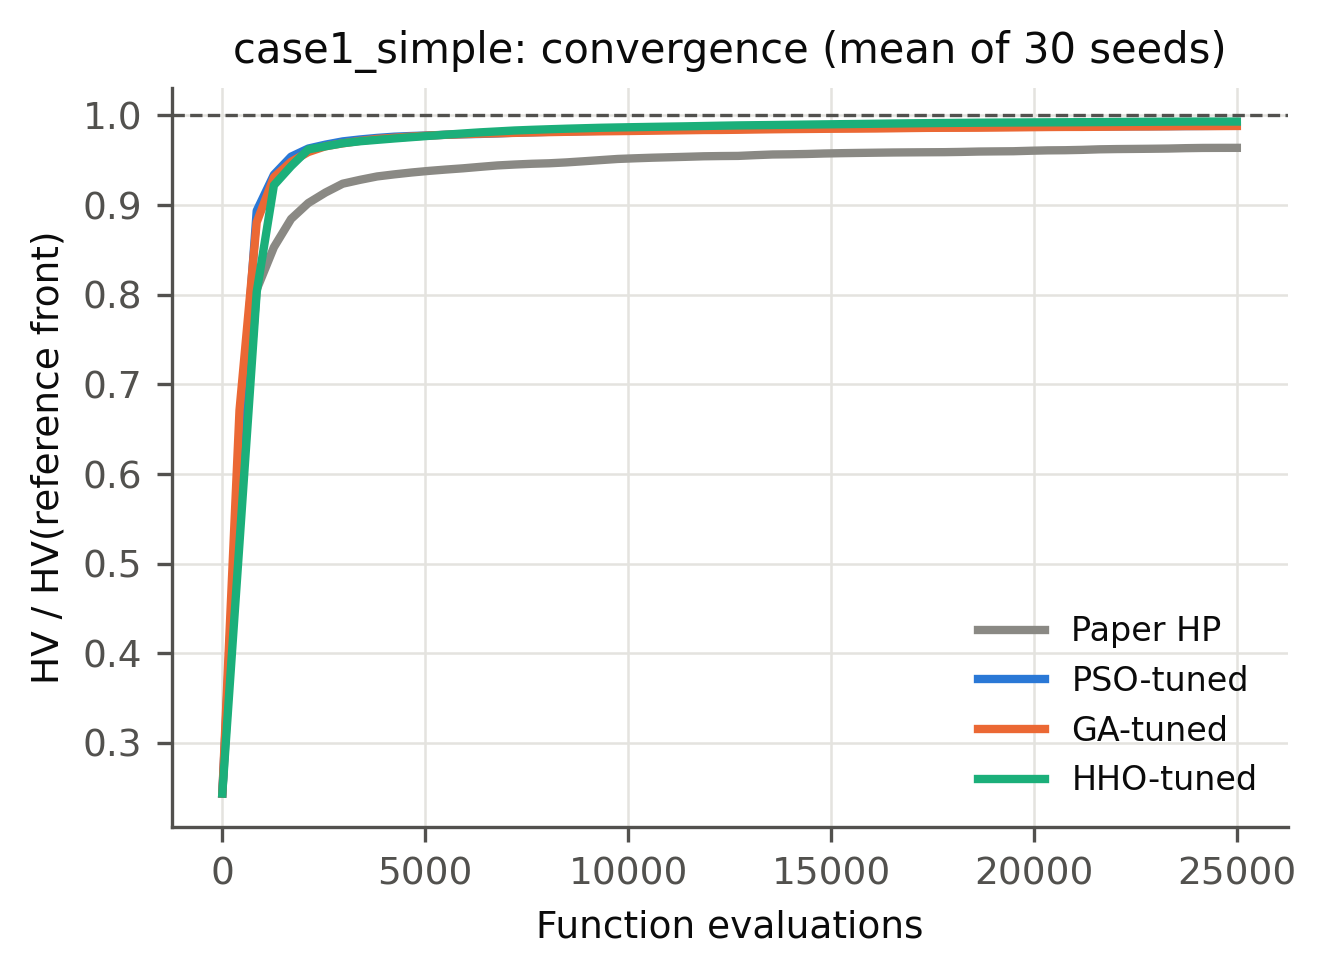

fig_case1_simple_layouts.png


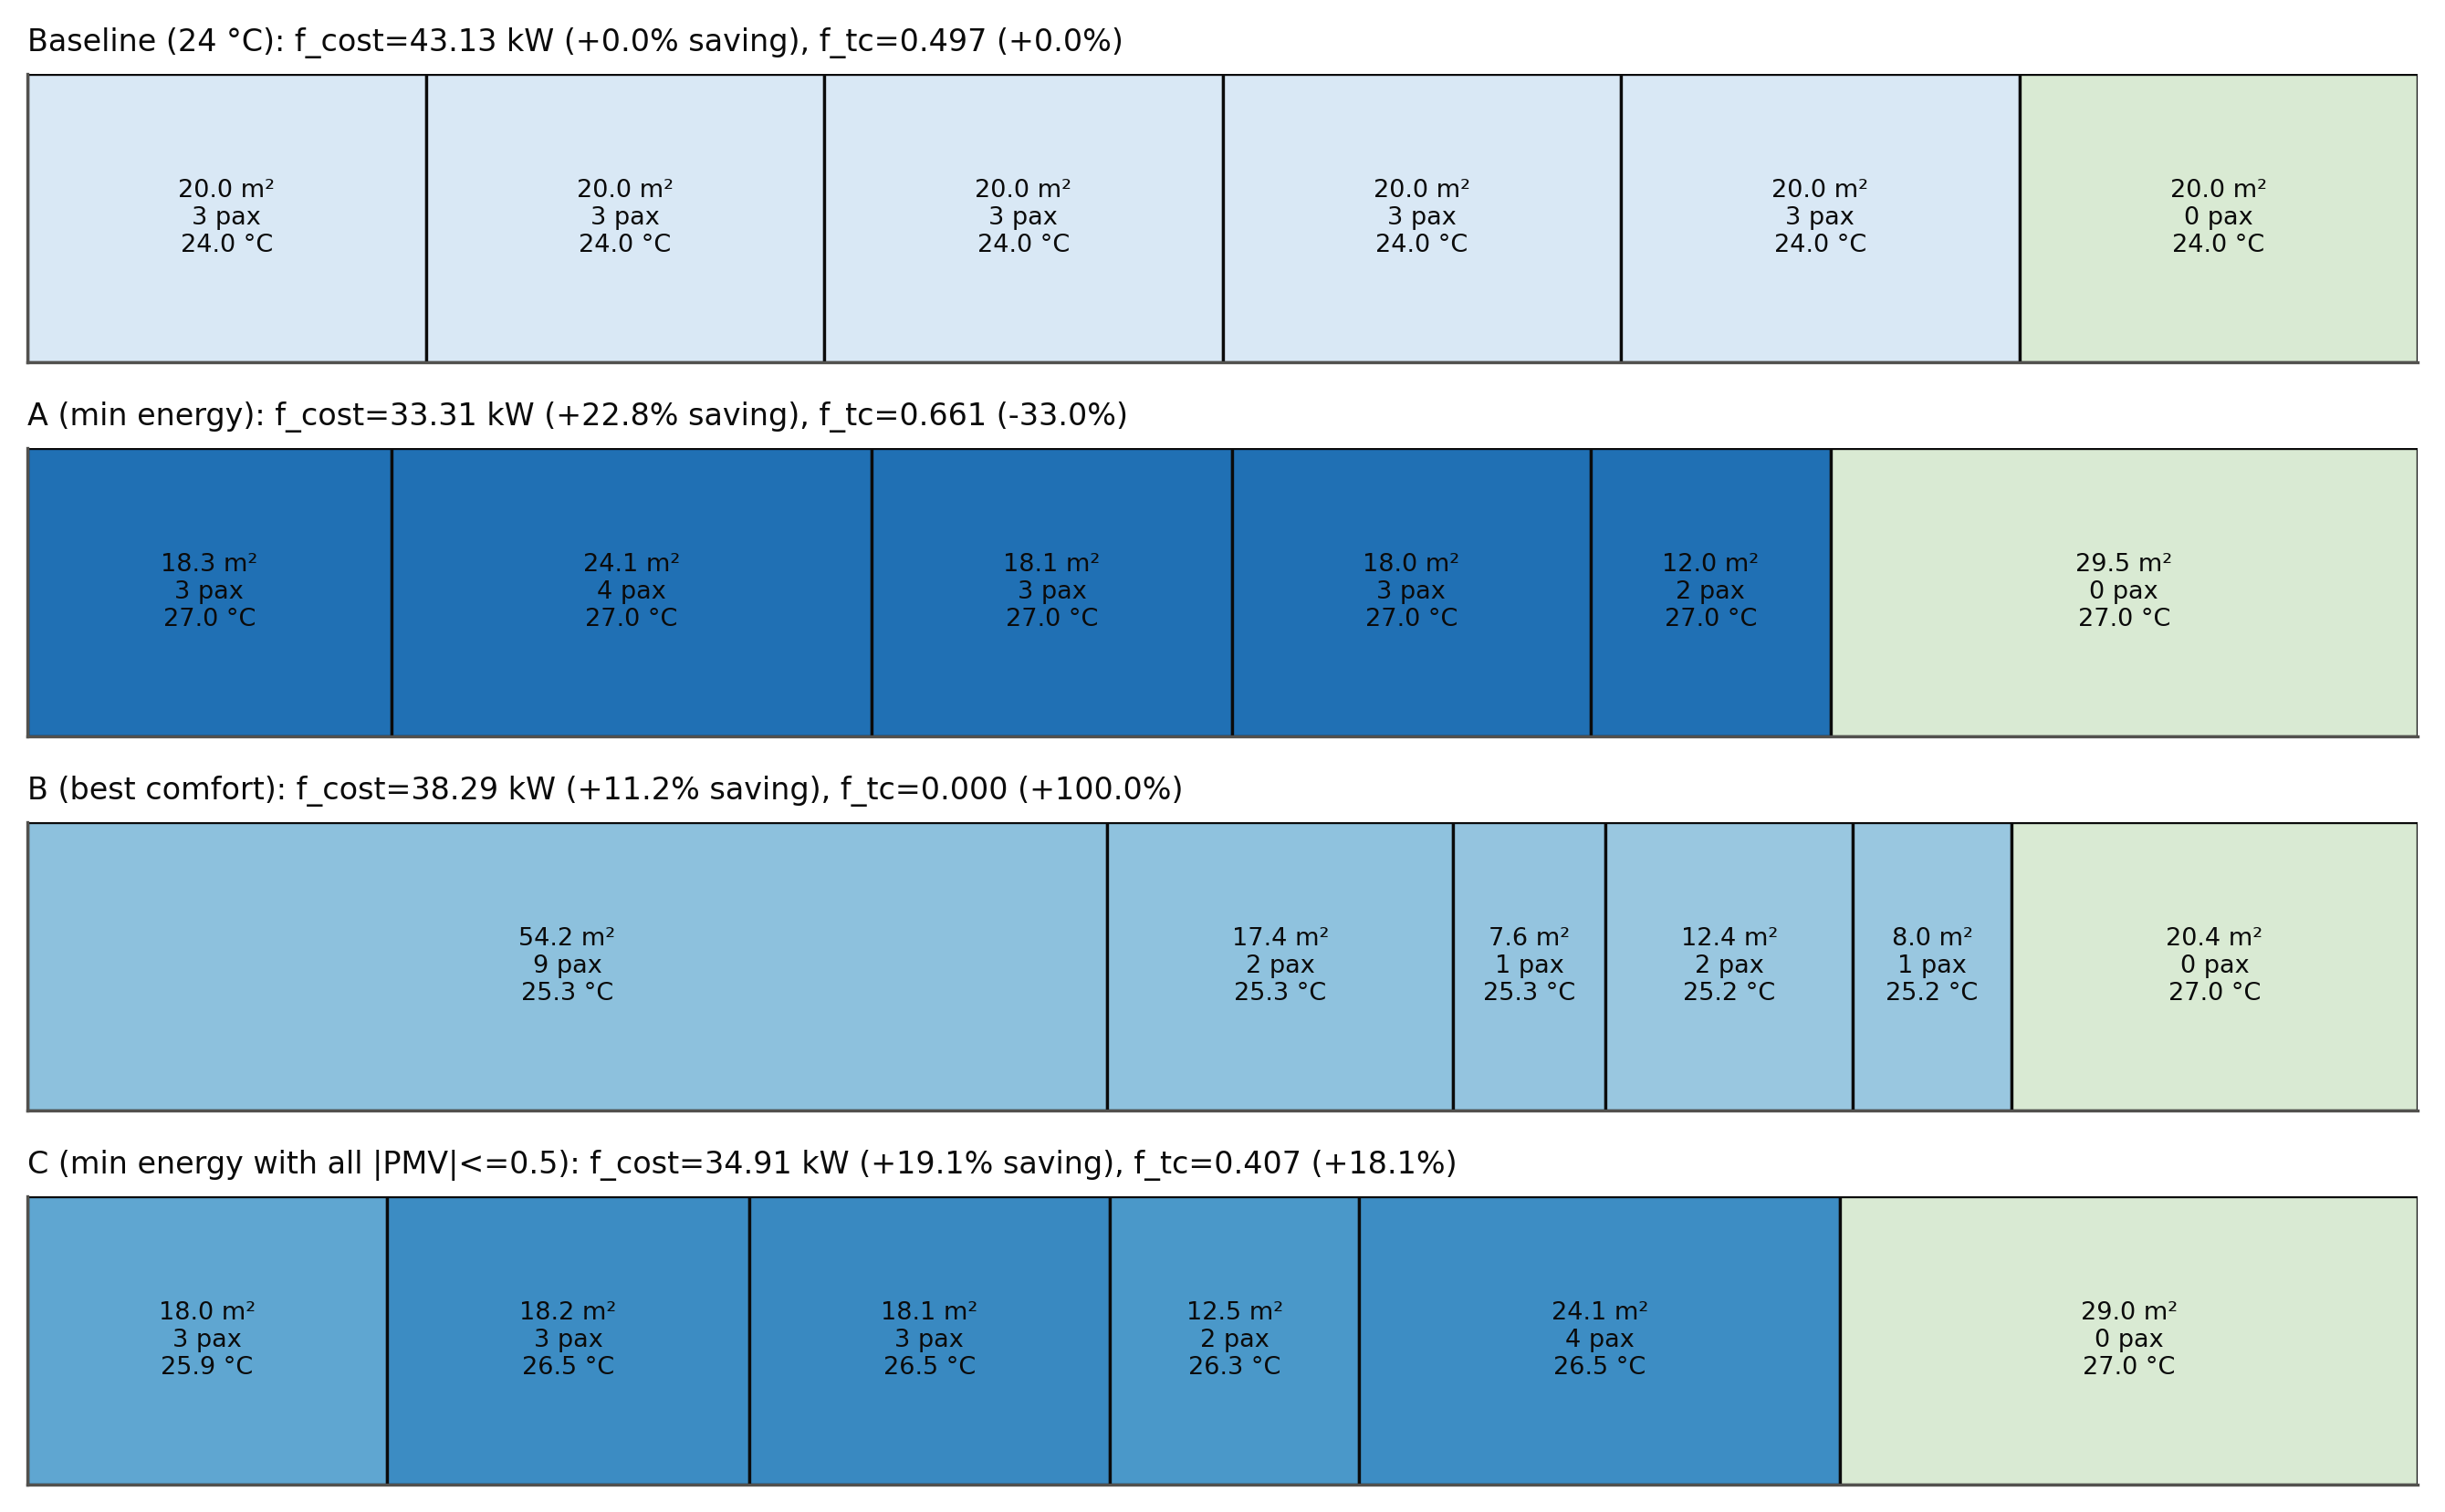

fig_case2_watson_pareto.png


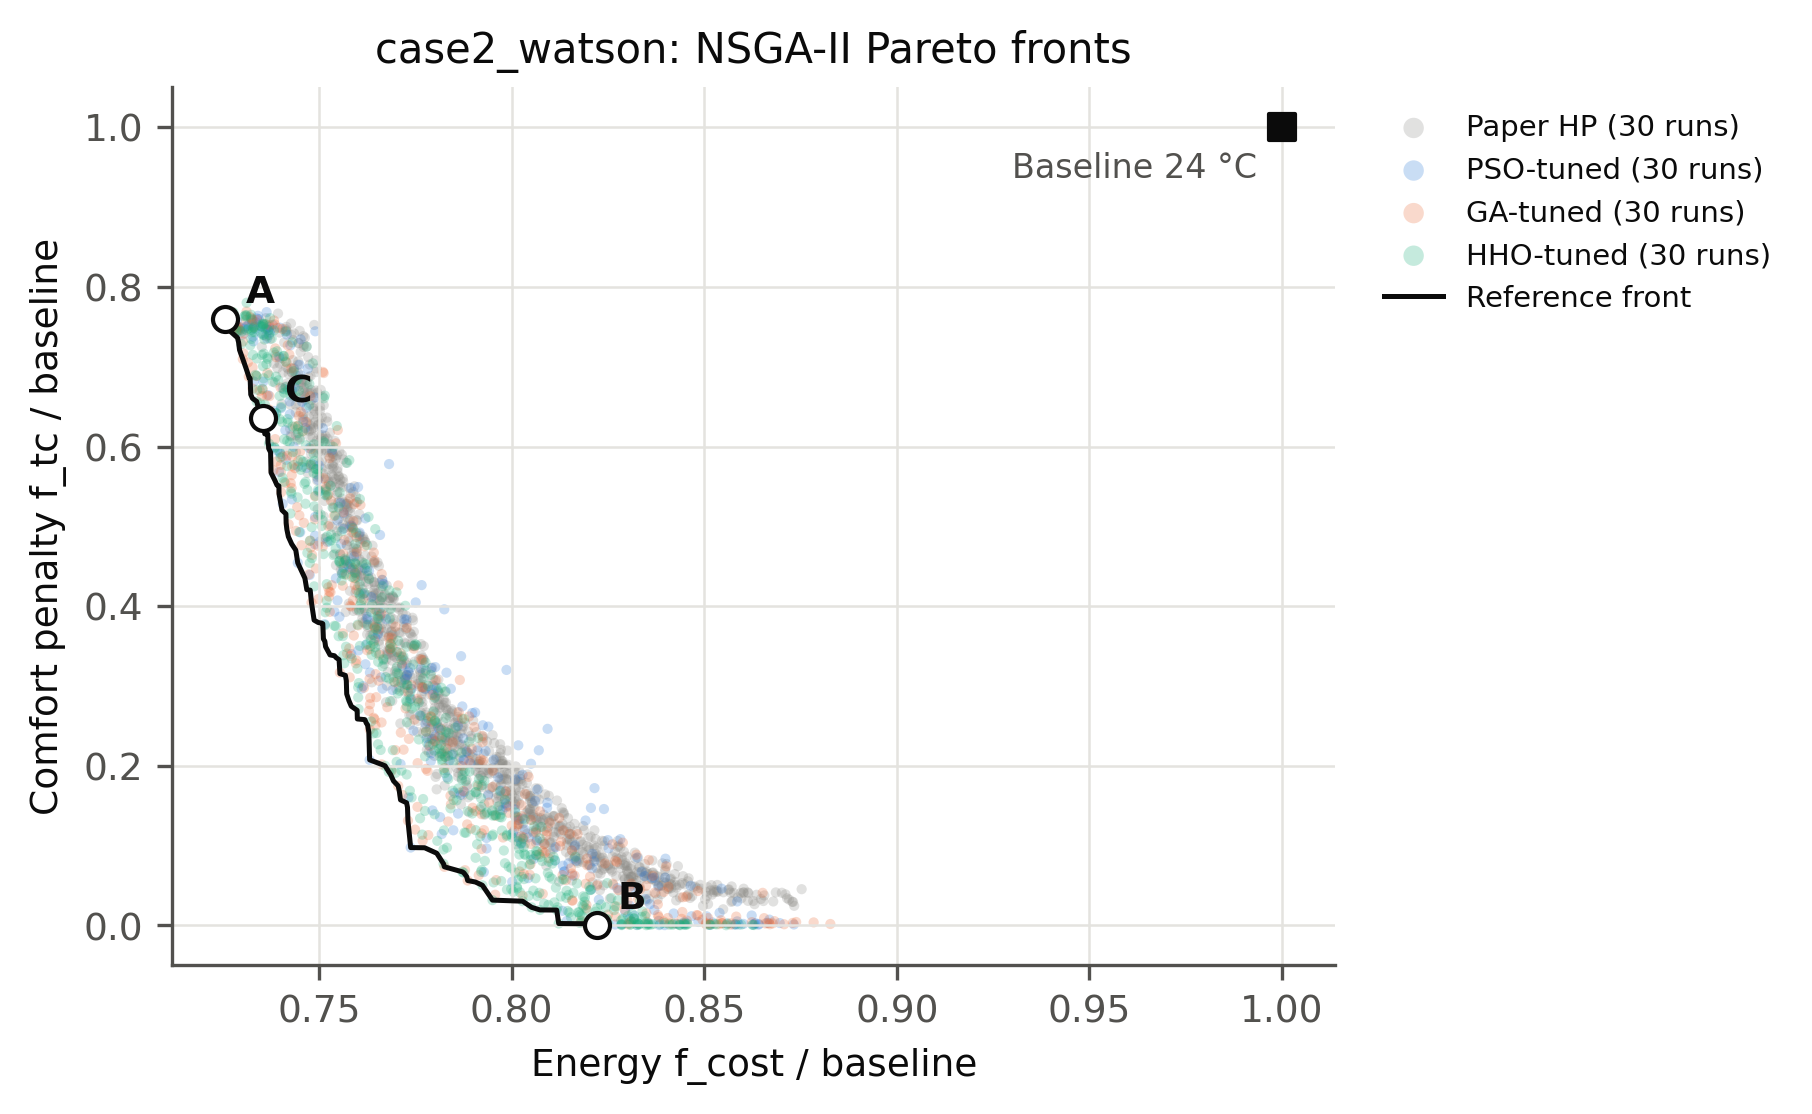

fig_case2_watson_hv_convergence.png


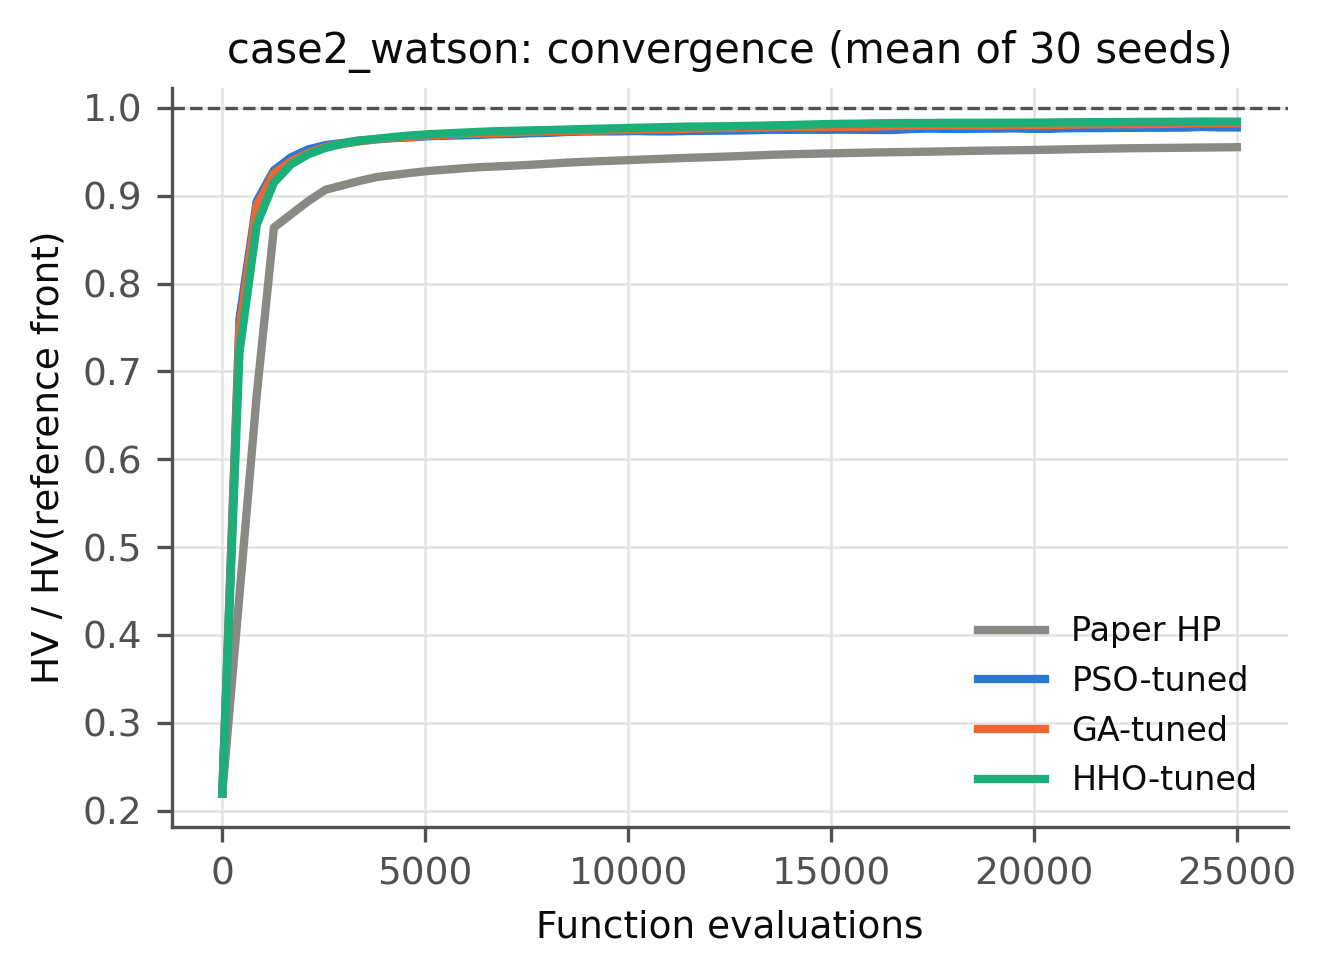

fig_case2_watson_layouts.png


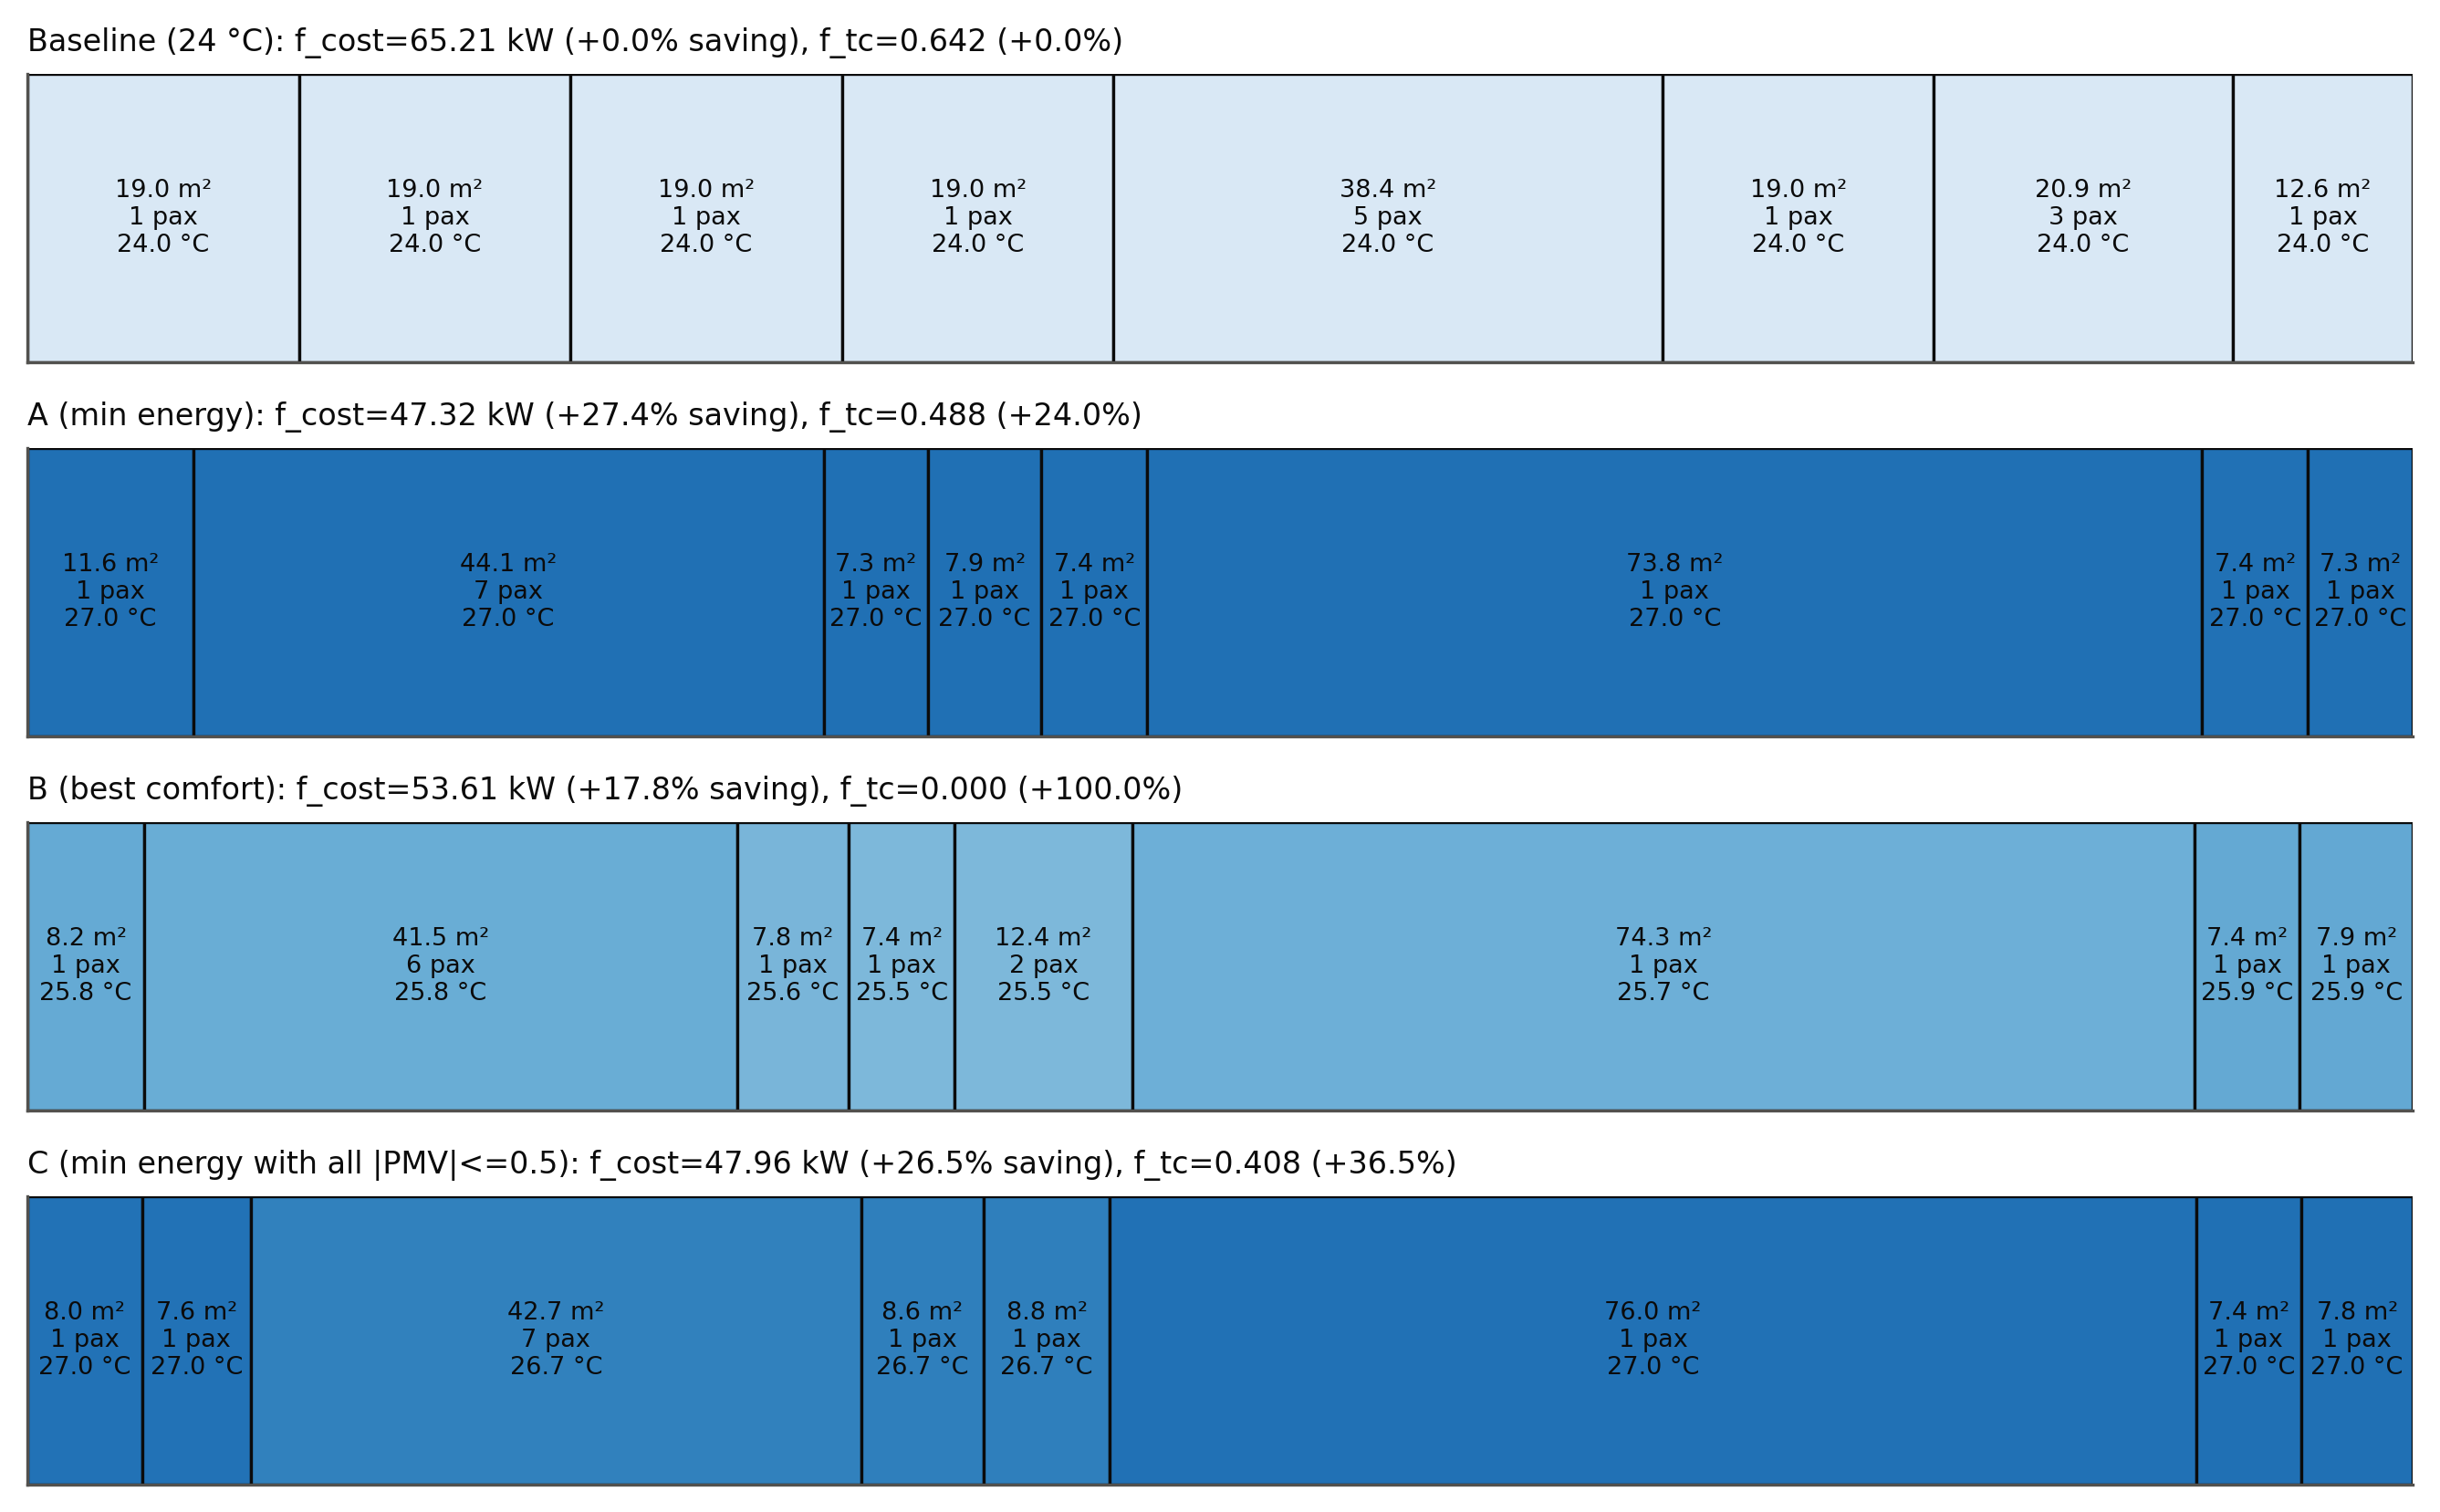

In [4]:
from IPython.display import Image, display
for f in ['fig_case1_simple_pareto.png', 'fig_case1_simple_hv_convergence.png', 'fig_case1_simple_layouts.png', 'fig_case2_watson_pareto.png', 'fig_case2_watson_hv_convergence.png', 'fig_case2_watson_layouts.png']:
    print(f)
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f), width=800))